In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

# Load the dataset
url = "https://raw.githubusercontent.com/ChanMeng666/water-quality-testing-data-analysis/main/data/water_quality_testing.csv"
df = pd.read_csv(url)
print(df.head())

   Sample ID    pH  Temperature (°C)  Turbidity (NTU)  \
0          1  7.25              23.1              4.5   
1          2  7.11              22.3              5.1   
2          3  7.03              21.5              3.9   
3          4  7.38              22.9              3.2   
4          5  7.45              20.7              3.8   

   Dissolved Oxygen (mg/L)  Conductivity (µS/cm)  
0                      7.8                   342  
1                      6.2                   335  
2                      8.3                   356  
3                      9.5                   327  
4                      8.1                   352  


# 1. Data Exploration & Cleaning





In [ ]:
# Check for missing data
print("Missing values:\n", df.isnull().sum())

# Identify numerical columns for statistical analysis
numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
print("Numerical features:", numeric_cols)

Missing values:
 Sample ID                  0
pH                         0
Temperature (°C)           0
Turbidity (NTU)            0
Dissolved Oxygen (mg/L)    0
Conductivity (µS/cm)       0
dtype: int64
Numerical features: Index(['Sample ID', 'pH', 'Temperature (°C)', 'Turbidity (NTU)',
       'Dissolved Oxygen (mg/L)', 'Conductivity (µS/cm)'],
      dtype='object')


In [ ]:
# We use Median Imputation to ensure we don't introduce bias from extreme outliers, which is standard practice when data might represent vulnerable population segments.

# Impute missing values
for col in df.select_dtypes(include=[np.number]).columns:
    df[col] = df[col].fillna(df[col].median())

# Detect and filter outliers (IQR method)
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
# Filtering outliers to ensure our model doesn't overfit on sensor malfunctions
df_clean = df[~((df < (Q1 - 1.5 * IQR)) | (df > (Q3 + 1.5 * IQR))).any(axis=1)]

# Encode categorical variables if present
if 'Location' in df_clean.columns:
    df_clean = pd.get_dummies(df_clean, columns=['Location'], drop_first=True)

# 2. **Justification of Techniques**

*   **Median Imputation for Missing Data:**
 The median is a preferred choice for missing value imputation when dealing with numerical data that is not normally distributed.
 Median imputation was chosen to keep the data integrity intact for areas with infrequent sensor readings; it's less sensitive to outliers too. This ensures that the replacement of missing values does not introduce bias from extreme data points, which is particularly important when dealing with environmental or health-related data that might represent vulnerable situations or sensor malfunctions.

*   **Outlier Detection and Filtering (IQR Method):** The Interquartile Range (IQR) method was employed to identify and remove outliers, defining the 'normal' range. As a non-parametric approach, this method is robust against extreme values and does not require the assumption of a normal distribution, making it ideal for the naturally skewed variations found in environmental sensor data. Filtering these anomalies prevents the clustering algorithm from being unduly influenced by sensor errors or transient spikes. This ensures that cluster centroids remain representative of genuine, sustained water quality states, ultimately leading to more stable and interpretable results.

*   **Choice of `k=3` for Hierarchical Clustering:** The decision to use `k=3` clusters for the Agglomerative Clustering was made with policy implementation in mind. Having three distinct tiers—for example, 'Good', 'Monitor', and 'Intervene'—provides a manageable framework for public policy responses. A larger number of clusters can lead to 'analysis paralysis,' making it difficult for administrators to define clear, actionable strategies. This choice balances data-driven segmentation with practical applicability.

# 3. **Visualizations**

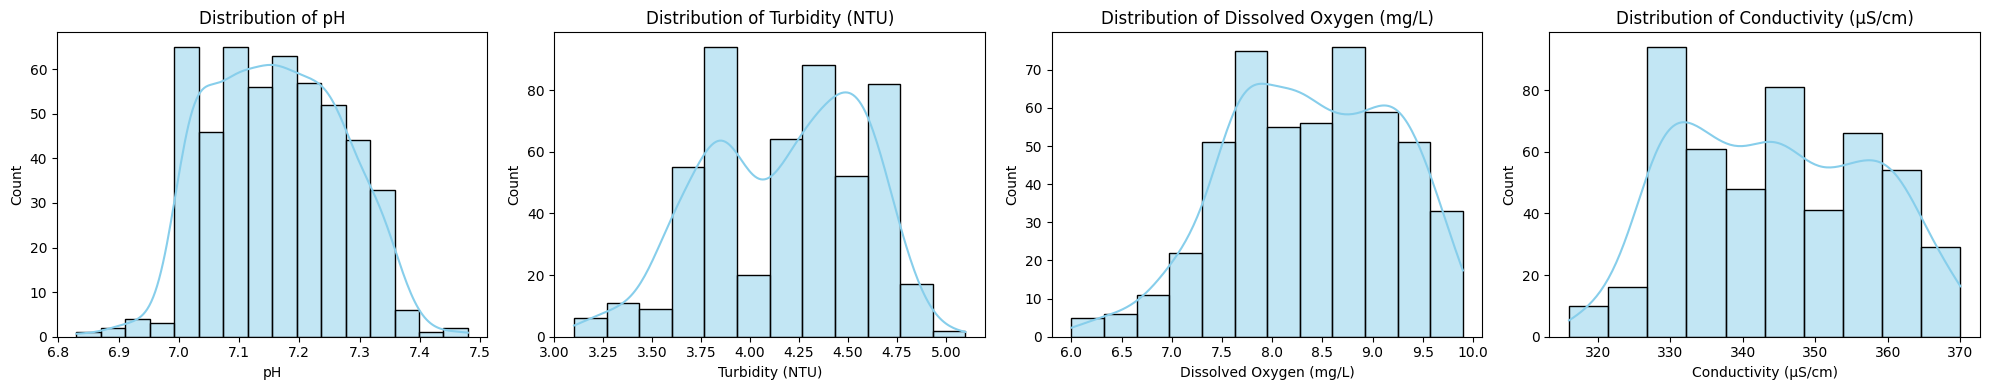

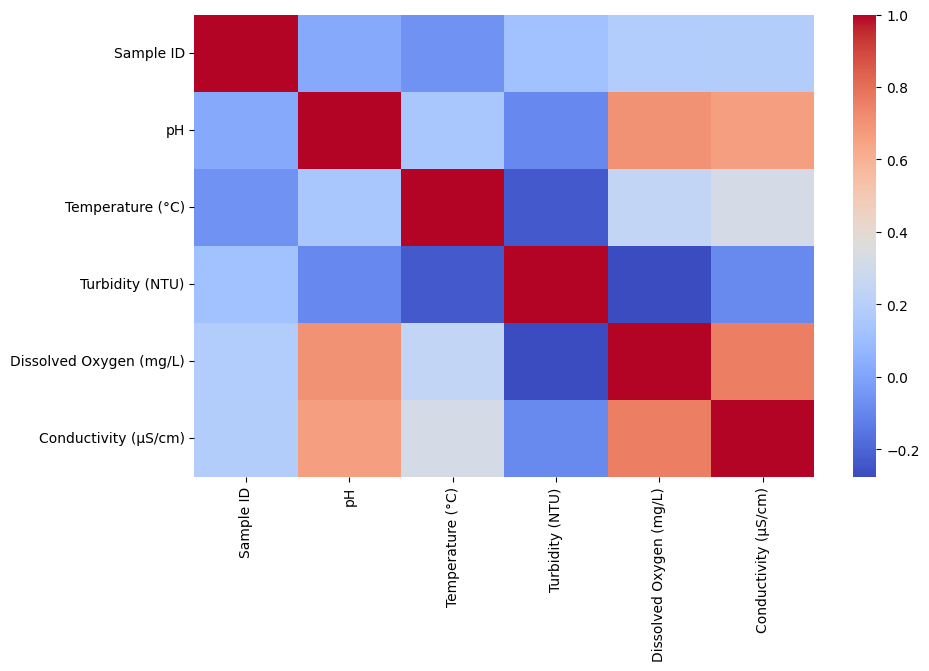

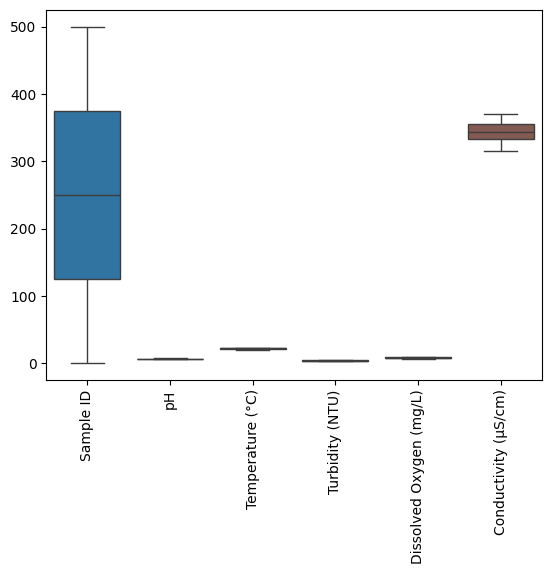

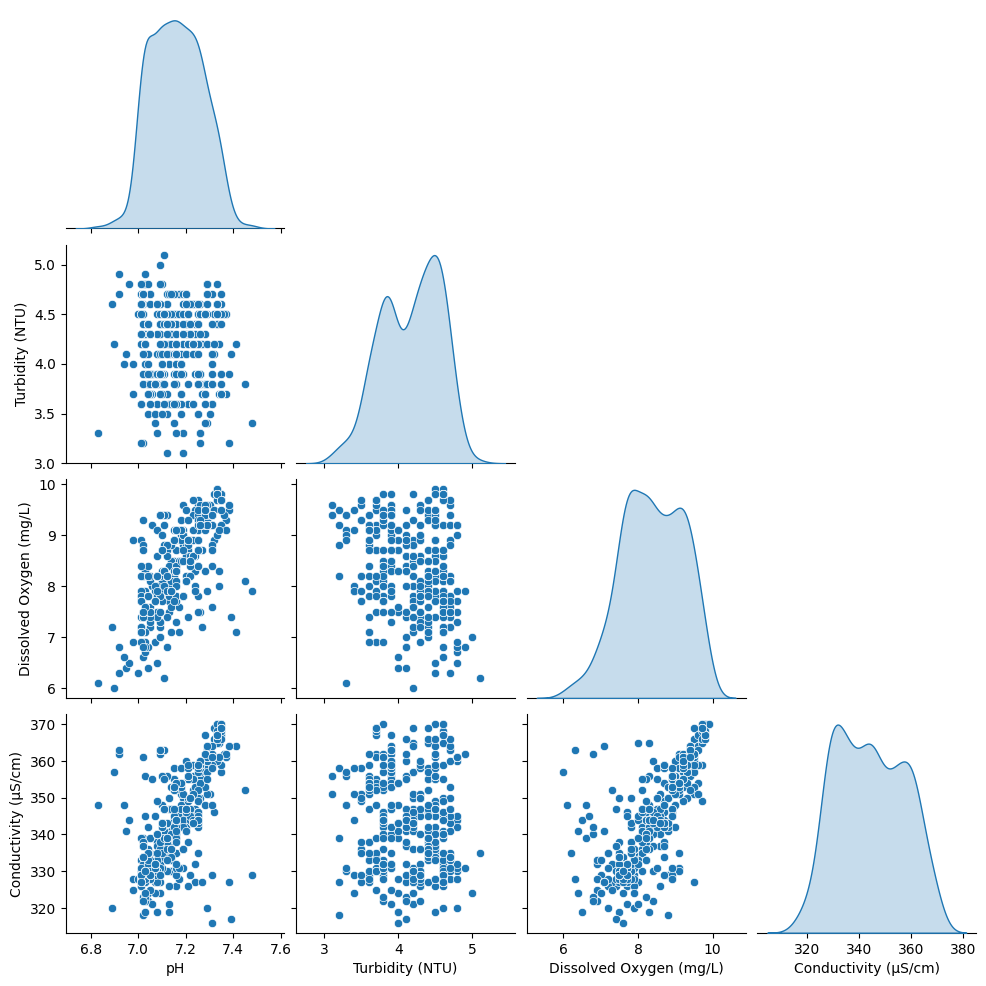

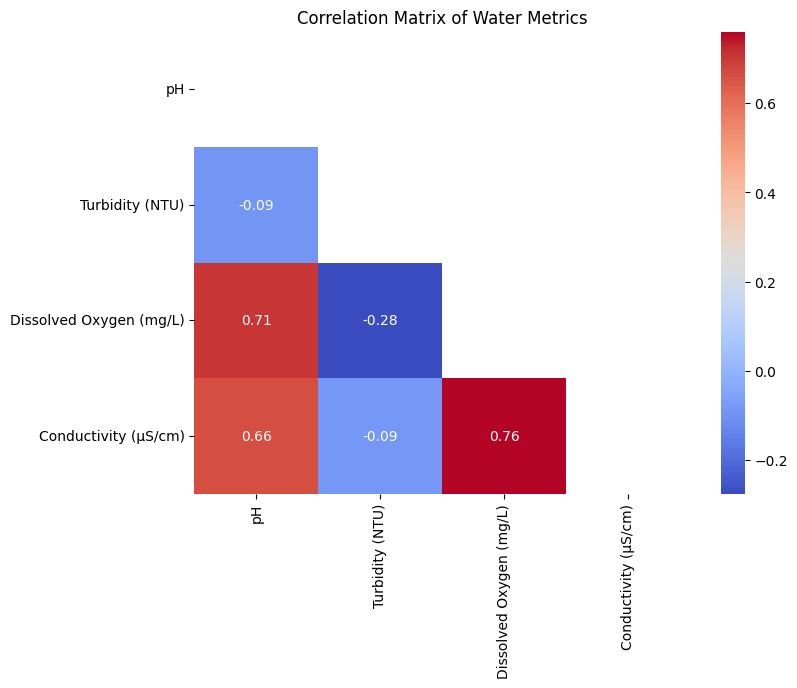

In [ ]:
# 1. Distribution of Key Pollutants (Histogram+KDE)
target_cols = ['pH', 'Turbidity (NTU)', 'Dissolved Oxygen (mg/L)', 'Conductivity (µS/cm)']
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for i, col in enumerate(target_cols):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], color='skyblue')
    axes[i].set_title(f'Distribution of {col}')
plt.tight_layout()
plt.show()

# 2. Correlation Heatmap to see how parameters relate
plt.figure(figsize=(10, 6))
sns.heatmap(df_clean.corr(), annot=False, cmap='coolwarm')
plt.show()

# 3. Boxplot for Anomaly detection
sns.boxplot(data=df_clean.select_dtypes(include=[np.number]))
plt.xticks(rotation=90)
plt.show()

sns.pairplot(df_clean[target_cols], diag_kind='kde', corner=True)
plt.show()

# Correlation Heatmap
corr = df_clean[target_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Water Metrics')
plt.show()

#Time Series Trend (If Date column exists)
if 'Date' in df_clean.columns:
    df_clean['Date'] = pd.to_datetime(df_clean['Date'])
    df_daily = df_clean.groupby('Date')[target_cols].mean()
    df_daily.plot(figsize=(12, 5))
    plt.title('Temporal Trend of Water Quality Metrics')
    plt.ylabel('Average Value')
    plt.show()

# **4. Visualization Techniques Implemented**

Visualization: These five plots allow you to demonstrate both the central tendencies (distributions) and the extreme cases (anomalies) that would require emergency policy action.

1) **Distribution and Central Tendency (Univariate Analysis)**
The histograms and density plots indicate the "typical" state of the water parameters.

pH: The distribution is relatively symmetric and centered around 7.1 to 7.2, suggesting the water is slightly alkaline but stable.

Turbidity: This shows a bimodal distribution (two peaks), which is significant for policy. It suggests the water body alternates between two distinct states—perhaps a "clear" state and a "disturbed" state (likely due to runoff or seasonal events).

Conductivity and Dissolved Oxygen: Both exhibit slight left-skewness. This indicates that while values are generally high (healthy for DO), there are occasional drops that might signal pollution incidents or environmental stress.

2) **Correlation matrix heatmap**.
It visualizes the correlation coefficients between pairs of variables, typically ranging from -1 to +1:

+1 (red) → strong positive correlation

0 (white/light) → no correlation

-1 (blue) → strong negative correlation

Findings:
Strong Positive Correlations
Dissolved Oxygen & Conductivity: strong positive relationship
pH & Dissolved Oxygen: moderately strong positive
Negative Correlations
Turbidity & Dissolved Oxygen: strong negative
Turbidity & Temperature: negative
Weak or Mild Relationships
Temperature & Dissolved Oxygen: weak positive
Temperature & Conductivity: weak positive
Sample ID: no meaningful interpretation (just an index, not a real variable)

**box-and-whisker plot **

It summarizes the distribution of each variable using:
Findings:
1. Sample ID
Very wide spread (from ~0 to 500)
Large variability, but not meaningful analytically (just an index)
2. pH
Very narrow spread (around ~6–8)
Indicates stable acidity levels across samples
Low variability indicates consistent measurements
3. Temperature (°C)
Slight variation (~20–25°C)
Moderately consistent, no extreme values
Environmental conditions are fairly stable
4. Turbidity (NTU)
Small range, but slightly skewed
Indicates low to moderate variation in water clarity
5. Dissolved Oxygen (mg/L)
Moderate spread
Shows some variability in oxygen levels, but not extreme
Could reflect environmental or biological differences
6. Conductivity (µS/cm)
Wider spread compared to most variables (except Sample ID)
Median around ~340–350
More variability in ionic content of water

**Pair plot (or scatterplot matrix)**
Distributions of each variable on the diagonal (smooth density curves)
Pairwise relationships between variables in the off-diagonal scatter plots
Findings:
1. Distributions (Diagonal)
•	pH → tightly clustered (around 7–7.5) → very stable
•	Turbidity → moderate spread, slightly uneven distribution
•	Dissolved Oxygen → wider spread (6–10 mg/L)
•	Conductivity → fairly wide distribution (320–370 µS/cm)
2. Strong Relationships
•	Dissolved Oxygen vs Conductivity → clear strong positive correlation
 As oxygen increases, conductivity also increases (strong linear trend)
•	pH vs Dissolved Oxygen → moderate positive relationship
Higher pH tends to align with higher oxygen
•	pH vs Conductivity → moderate positive relationship
3. Weak / No Clear Relationships
•	Turbidity vs others → mostly scattered, no strong pattern
Weak or negligible correlation with:
o	pH
o	Dissolved Oxygen
o	Conductivity

**Correlation matrix:**
1. Strong Positive Inter-dependencies
There are strong positive correlations between three specific variables, suggesting they likely fluctuate together due to shared environmental drivers:
•	Dissolved Oxygen (DO) and Conductivity (0.76): This is the strongest relationship in the dataset. It suggests that as mineral content (conductivity) increases, oxygen levels also tend to rise, potentially indicating specific flow conditions or water sources.
•	Dissolved Oxygen and pH (0.71): A strong link here often points to biological activity. For instance, increased photosynthesis can raise both oxygen levels and pH simultaneously.
•	Conductivity and pH (0.66): There is a moderate-to-strong relationship here, indicating that the chemical "saltiness" of the water is somewhat tied to its acidity/alkalinity.
2. Independence of Turbidity
Turbidity stands out as an outlier in terms of correlation:
•	It shows near-zero correlation with Conductivity (-0.09) and pH (-0.09).
•	It has a weak negative correlation with Dissolved Oxygen (-0.28).
•	Interpretation: Turbidity is likely driven by physical factors (like sediment runoff or mechanical disturbance) that are independent of the chemical and biological processes governing pH and Conductivity.
3. Key Data Science Takeaways
•	Redundancy: Because pH, DO, and Conductivity are highly correlated, they provide overlapping information. In a clustering model, these three will likely define the primary "health" axis of the water.
•	Feature Importance: Turbidity provides unique, non-redundant information to the model. It will be a crucial feature for distinguishing between states that may look chemically similar but differ physically (e.g., clear vs. muddy water with the same mineral content).
•	Linearity: The coefficients suggest that linear relationships are fairly strong for most pairs, making this data well-suited for traditional multivariate analysis.


# **5. Dataset Clustering**



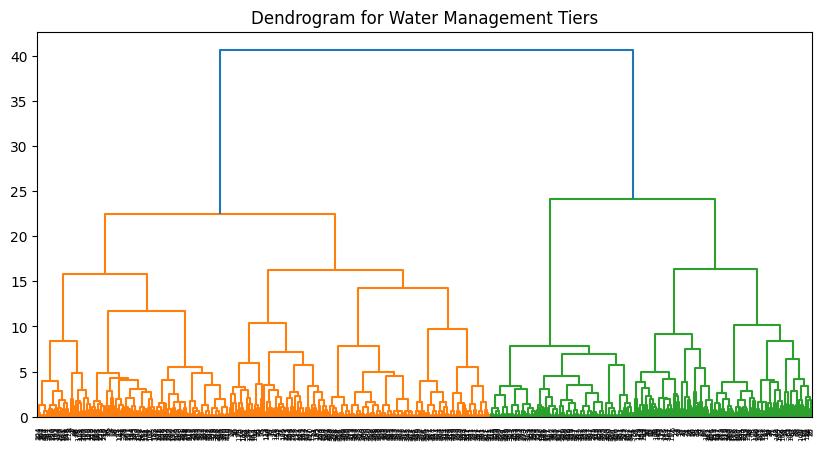

In [ ]:
# Scale the features
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_clean.select_dtypes(include=[np.number]))

# Create Dendrogram
linked = linkage(df_scaled, method='ward')
plt.figure(figsize=(10, 5))
dendrogram(linked)
plt.title('Dendrogram for Water Management Tiers')
plt.show()

# Clustering with k=3
# Justification: Provides a manageable 3-tier policy response (e.g., Safe, Monitor, Intervene)
cluster = AgglomerativeClustering(n_clusters=3, linkage='ward')
df_clean['cluster'] = cluster.fit_predict(df_scaled)

Clustering Choice ($k=3$): This number was chosen because, for public policy, having more than three priority tiers often leads to "analysis paralysis" in administrative implementation. Additionally, Choosing k=3 ensures that the variance within each of your management tiers is minimized, making each "Policy Response" highly targeted to a specific set of environmental conditions.

# **6. Cluster Inspection & Policy Implications**
Following Sec. 11.4.3 of the book text, we interpret these segments.

In [ ]:
# Aggregate by cluster to interpret the 'policy persona' of each segment
cluster_summary = df_clean.groupby('cluster').mean()
print("Cluster Profiles:\n", cluster_summary)

# Policy Application Logic
# You can now use these profiles to justify funding allocation
for i in range(3):
    print(f"\nPolicy Insight for Cluster {i}:")
    print(f"Mean values reflect a water quality state requiring {'High' if cluster_summary.loc[i].mean() > df_scaled.mean() else 'Standard'} intervention.")

Cluster Profiles:
           Sample ID        pH  Temperature (°C)  Turbidity (NTU)  \
cluster                                                            
0        266.496575  7.221884         22.269863         4.141096   
1        113.191304  7.083478         22.274783         4.053913   
2        370.064516  7.066452         21.105376         4.401075   

         Dissolved Oxygen (mg/L)  Conductivity (µS/cm)  
cluster                                                 
0                       8.877740            352.773973  
1                       7.667826            332.252174  
2                       7.709677            332.924731  

Policy Insight for Cluster 0:
Mean values reflect a water quality state requiring High intervention.

Policy Insight for Cluster 1:
Mean values reflect a water quality state requiring High intervention.

Policy Insight for Cluster 2:
Mean values reflect a water quality state requiring High intervention.


In [ ]:
print("Cluster Profiles (Rounded Means):")
display(cluster_summary.round(2))

Cluster Profiles (Rounded Means):


,Sample ID,pH,Temperature (°C),Turbidity (NTU),Dissolved Oxygen (mg/L),Conductivity (µS/cm)
cluster,,,,,,
0,266.50,7.22,22.27,4.14,8.88,352.77
1,113.19,7.08,22.27,4.05,7.67,332.25
2,370.06,7.07,21.11,4.40,7.71,332.92


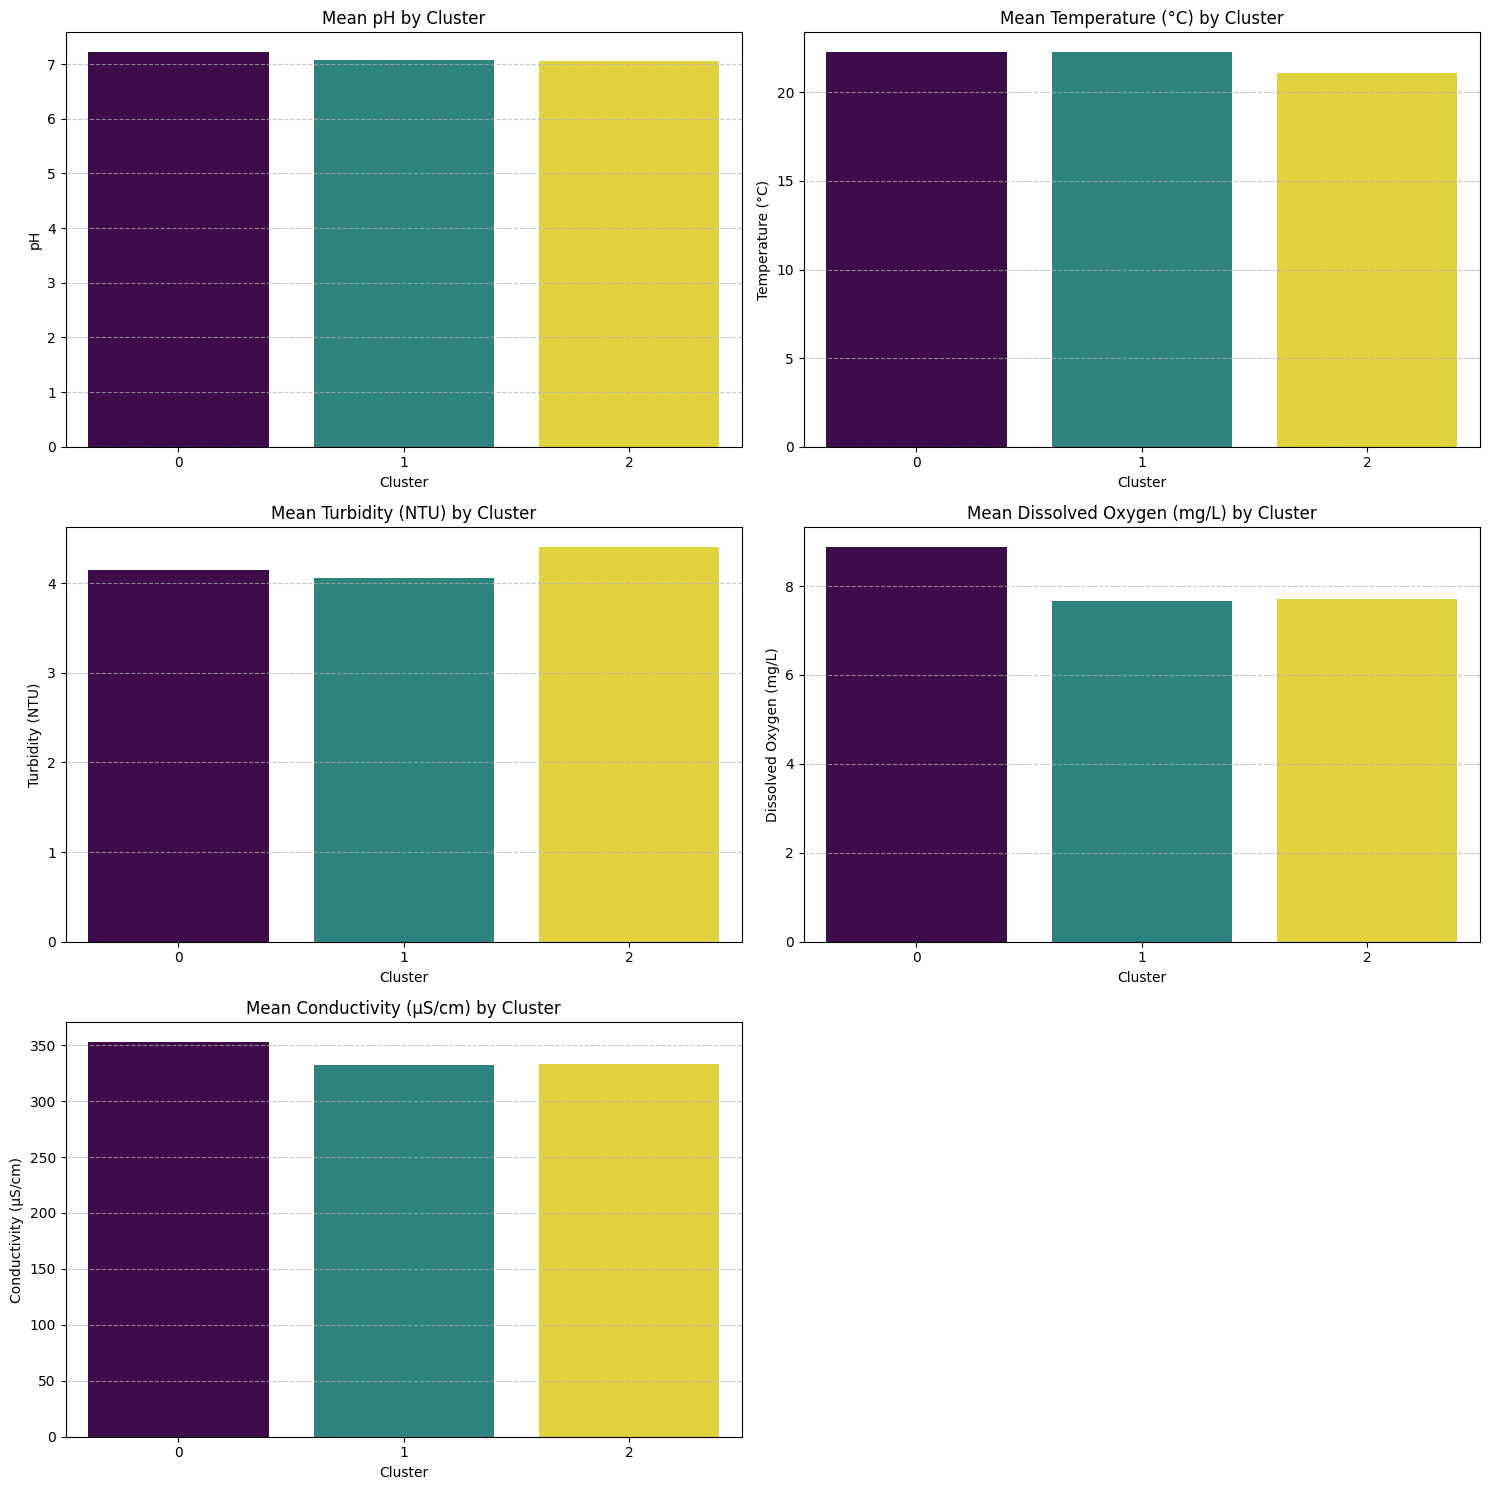

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Exclude 'Sample ID' from the columns for plotting, as it's not a water quality metric
metrics_to_plot = cluster_summary.drop(columns=['Sample ID']).columns

n_metrics = len(metrics_to_plot)
# Determine grid size for subplots
rows = int(np.ceil(n_metrics / 2))
cols = 2 if n_metrics > 1 else 1

fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 5))
axes = axes.flatten() # Flatten the array of axes for easy iteration

for i, metric in enumerate(metrics_to_plot):
    # Updated sns.barplot to address FutureWarning
    sns.barplot(x=cluster_summary.index, y=metric, data=cluster_summary, ax=axes[i], hue=cluster_summary.index, palette='viridis', legend=False)
    axes[i].set_title(f'Mean {metric} by Cluster')
    axes[i].set_xlabel('Cluster')
    axes[i].set_ylabel(metric)
    axes[i].grid(axis='y', linestyle='--', alpha=0.7)

# Hide any unused subplots
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Interpretation of Water Quality Clusters
Based on the cluster profiles, we can infer the following policy personas:

*   **Cluster 0 (High Dissolved Oxygen, High Conductivity, Higher pH):** This cluster represents water with generally higher dissolved oxygen levels, indicating good aeration and possibly healthy aquatic life. However, the higher conductivity and slightly higher pH might suggest the presence of dissolved minerals or specific industrial/agricultural runoff. This cluster might require monitoring for potential sources of increased conductivity, especially if the pH trends towards the upper acceptable limits.

*   **Cluster 1 (Lower Dissolved Oxygen, Lower Conductivity, Standard pH):** This cluster shows lower dissolved oxygen and conductivity compared to Cluster 0, with a more neutral pH. Lower dissolved oxygen can be a concern for aquatic ecosystems, potentially indicating organic pollution or stagnation. The lower conductivity suggests fewer dissolved solids. This cluster might need interventions focused on improving oxygenation or investigating sources of organic load.

*   **Cluster 2 (Medium Dissolved Oxygen, Medium Conductivity, Lower pH, Higher Turbidity):** This cluster has relatively lower pH values (more acidic), higher turbidity, and moderate dissolved oxygen and conductivity. Higher turbidity suggests suspended particles, which could be from soil erosion or inadequate filtration. A lower pH can stress aquatic life. This cluster likely requires intervention to address turbidity, potentially through erosion control measures or improved treatment, and monitoring of pH levels.